# Lab 4: Regression Analysis with Regularization Techniques

**Name:** Sai Sravani P
**Course:** MSCS 634 – Advanced Big Data and Data Mining
**Lab Assignment:** Lab 4 – Linear, Multiple, Polynomial, Ridge and Lasso Regression on the Diabetes Dataset

---

### Objectives
1. Prepare and explore the Diabetes dataset from `sklearn.datasets`.
2. Build **Simple Linear**, **Multiple**, and **Polynomial** regression models.
3. Apply **Ridge (L2)** and **Lasso (L1)** regularization and study the effect of the `alpha` parameter.
4. Evaluate every model with **MAE, MSE, RMSE and R²** and visualize the results.
5. Compare all models and discuss overfitting, underfitting, and insights about the data.

## 0. Setup – Import Libraries
All libraries used in the lab are imported once here. A fixed `RANDOM_STATE` keeps every train/test split and result reproducible.

In [1]:
# Core data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: data, models, preprocessing, evaluation
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")          # hide convergence warnings from very small Lasso alphas

RANDOM_STATE = 42                          # reproducibility
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

### Helper function for evaluation
To avoid repeating code, `evaluate_model()` computes all four required metrics for a set of predictions and stores the result in a shared `results` list. That list is used at the end for the model-comparison table.

In [2]:
results = []   # collects test-set metrics for every model built in the lab

def evaluate_model(name, y_true, y_pred, store=True):
    # Compute MAE, MSE, RMSE and R^2 for one model's predictions.
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    metrics = {"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}
    if store:
        results.append(metrics)
    print(f"{name}\n  MAE : {mae:8.2f}\n  MSE : {mse:8.2f}\n  RMSE: {rmse:8.2f}\n  R²  : {r2:8.4f}")
    return metrics

def plot_actual_vs_pred(y_true, y_pred, title, ax=None, color="#2a6fdb"):
    # Scatter of actual vs predicted values with the ideal y = x reference line.
    ax = ax or plt.gca()
    ax.scatter(y_true, y_pred, alpha=0.65, edgecolor="white", color=color)
    lims = [min(y_true.min(), y_pred.min()) - 10, max(y_true.max(), y_pred.max()) + 10]
    ax.plot(lims, lims, "--", color="gray", lw=1.5, label="Perfect prediction (y = x)")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("Actual disease progression")
    ax.set_ylabel("Predicted disease progression")
    ax.set_title(title)
    ax.legend(loc="upper left")
    return ax

## Step 1: Data Preparation

### 1.1 Load the dataset
The Diabetes dataset contains **442 patients** and **10 baseline variables** (age, sex, BMI, average blood pressure and six blood-serum measurements). The target is a quantitative measure of **disease progression one year after baseline**.

In [3]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame.copy()                 # features + 'target' column in one DataFrame

print("Shape of dataset:", df.shape)
print("\nFeature names:", diabetes.feature_names)
df.head()

Shape of dataset: (442, 11)

Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### 1.2 Data types, summary statistics

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [5]:
df.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.0000,0.0476,-0.1072,-0.0373,0.0054,0.0381,0.1107
sex,442.0,0.0000,0.0476,-0.0446,-0.0446,-0.0446,0.0507,0.0507
bmi,442.0,-0.0000,0.0476,-0.0903,-0.0342,-0.0073,0.0312,0.1706
bp,442.0,-0.0000,0.0476,-0.1124,-0.0367,-0.0057,0.0356,0.1320
s1,442.0,-0.0000,0.0476,-0.1268,-0.0342,-0.0043,0.0284,0.1539
s2,442.0,0.0000,0.0476,-0.1156,-0.0304,-0.0038,0.0298,0.1988
s3,442.0,-0.0000,0.0476,-0.1023,-0.0351,-0.0066,0.0293,0.1812
s4,442.0,-0.0000,0.0476,-0.0764,-0.0395,-0.0026,0.0343,0.1852
s5,442.0,0.0000,0.0476,-0.1261,-0.0332,-0.0019,0.0324,0.1336
s6,442.0,0.0000,0.0476,-0.1378,-0.0332,-0.0011,0.0279,0.1356


### 1.3 Data cleaning – missing values, duplicates, outliers

In [6]:
# Missing values per column
missing = df.isnull().sum()
print("Missing values per column:\n", missing.to_string())
print("\nTotal missing values:", missing.sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Outlier check with the IQR rule (count only – we do not remove them, see explanation below)
Q1, Q3 = df.quantile(0.25), df.quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).sum()
print("\nIQR-based outlier counts per column:\n", outlier_counts.to_string())

Missing values per column:
 age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0

Total missing values: 0
Duplicate rows: 0

IQR-based outlier counts per column:
 age       0
sex       0
bmi       3
bp        0
s1        8
s2        7
s3        7
s4        2
s5        4
s6        9
target    0


**Cleaning decisions**
- **Missing values:** none – no imputation is needed.
- **Duplicates:** none – every row is a unique patient.
- **Outliers:** a small number of points fall outside the 1.5×IQR range (mainly in the serum measurements `s1`–`s4` and `s6`). These are realistic clinical values, not data-entry errors, and the dataset is small (442 rows), so removing them would throw away real information. **They are kept.**
- **Scaling:** features are pre-scaled by scikit-learn, so no further transformation is required for linear models. Polynomial features will be standardized inside a pipeline later.

The dataset is therefore clean and ready for modeling.

### 1.4 Train / test split
One split is shared by **every** model so the comparison is fair. 80% of the data (353 rows) is used for training and 20% (89 rows) for testing.

In [11]:
X = df[diabetes.feature_names]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Training set:", X_train.shape, " Test set:", X_test.shape)

Training set: (353, 10)  Test set: (89, 10)


## Step 2: Simple Linear Regression

A simple linear regression models the target as a straight-line function of **one** feature:

$$\hat{y} = \beta_0 + \beta_1 \cdot \text{bmi}$$

We use `bmi`, the single most correlated feature.

**Train/test split:** the model uses the 80/20 split created in Section 1.6 (353 training rows, 89 test rows). The same split is reused for every model in the lab so all results can be compared fairly.

In [12]:
# Use only the BMI column (double brackets keep it 2-D, as scikit-learn expects)
X_train_bmi, X_test_bmi = X_train[["bmi"]], X_test[["bmi"]]

slr = LinearRegression()
slr.fit(X_train_bmi, y_train)
y_pred_slr = slr.predict(X_test_bmi)

print(f"Intercept (β0): {slr.intercept_:.2f}")
print(f"Slope     (β1): {slr.coef_[0]:.2f}\n")
_ = evaluate_model("Simple Linear (BMI)", y_test, y_pred_slr)

Intercept (β0): 152.00
Slope     (β1): 998.58

Simple Linear (BMI)
  MAE :    52.26
  MSE :  4061.83
  RMSE:    63.73
  R²  :   0.2334


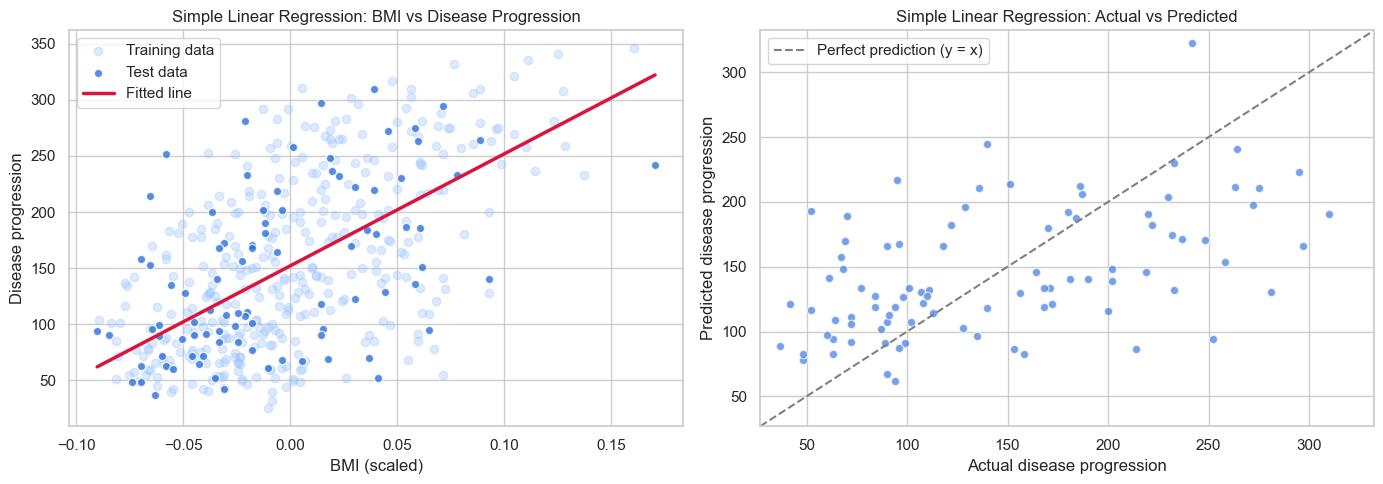

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) regression line over the data
axes[0].scatter(X_train_bmi, y_train, alpha=.35, label="Training data", color="#9ec5fe")
axes[0].scatter(X_test_bmi, y_test, alpha=.8, label="Test data", color="#2a6fdb", edgecolor="white")
x_line = np.linspace(X["bmi"].min(), X["bmi"].max(), 100).reshape(-1, 1)
axes[0].plot(x_line, slr.predict(pd.DataFrame(x_line, columns=["bmi"])), color="crimson", lw=2.5, label="Fitted line")
axes[0].set_xlabel("BMI (scaled)"); axes[0].set_ylabel("Disease progression")
axes[0].set_title("Simple Linear Regression: BMI vs Disease Progression"); axes[0].legend()

# (b) actual vs predicted
plot_actual_vs_pred(y_test, y_pred_slr, "Simple Linear Regression: Actual vs Predicted", ax=axes[1])
plt.tight_layout(); plt.show()

**Interpretation**
- The positive slope confirms that **higher BMI is associated with faster disease progression**.
- With R² ≈ 0.23 on the test set, BMI alone explains only about a quarter of the variation in the target. The RMSE (~64) is only slightly below the target's standard deviation (~77).
- Training R² is also low (≈ 0.37), so the model performs poorly on *both* sets.
- In the actual-vs-predicted plot the predictions are compressed into a narrow band and do not follow the diagonal well, meaning the model **underfits**: one feature cannot capture the complexity of disease progression. This motivates using more features.

## Step 3: Multiple Regression

Multiple regression uses **all 10 features**:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_{10} x_{10}$$

In [14]:
mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred_mlr = mlr.predict(X_test)

_ = evaluate_model("Multiple Linear (all 10)", y_test, y_pred_mlr)

# Training performance – used to check for overfitting
print(f"\nTraining R²: {r2_score(y_train, mlr.predict(X_train)):.4f}")

# 5-fold cross-validation on the training set gives a more robust estimate than one split
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_r2 = cross_val_score(LinearRegression(), X_train, y_train, cv=cv, scoring="r2")
print(f"5-fold CV R² (train set): {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")

Multiple Linear (all 10)
  MAE :    42.79
  MSE :  2900.19
  RMSE:    53.85
  R²  :   0.4526

Training R²: 0.5279
5-fold CV R² (train set): 0.4804 ± 0.0409


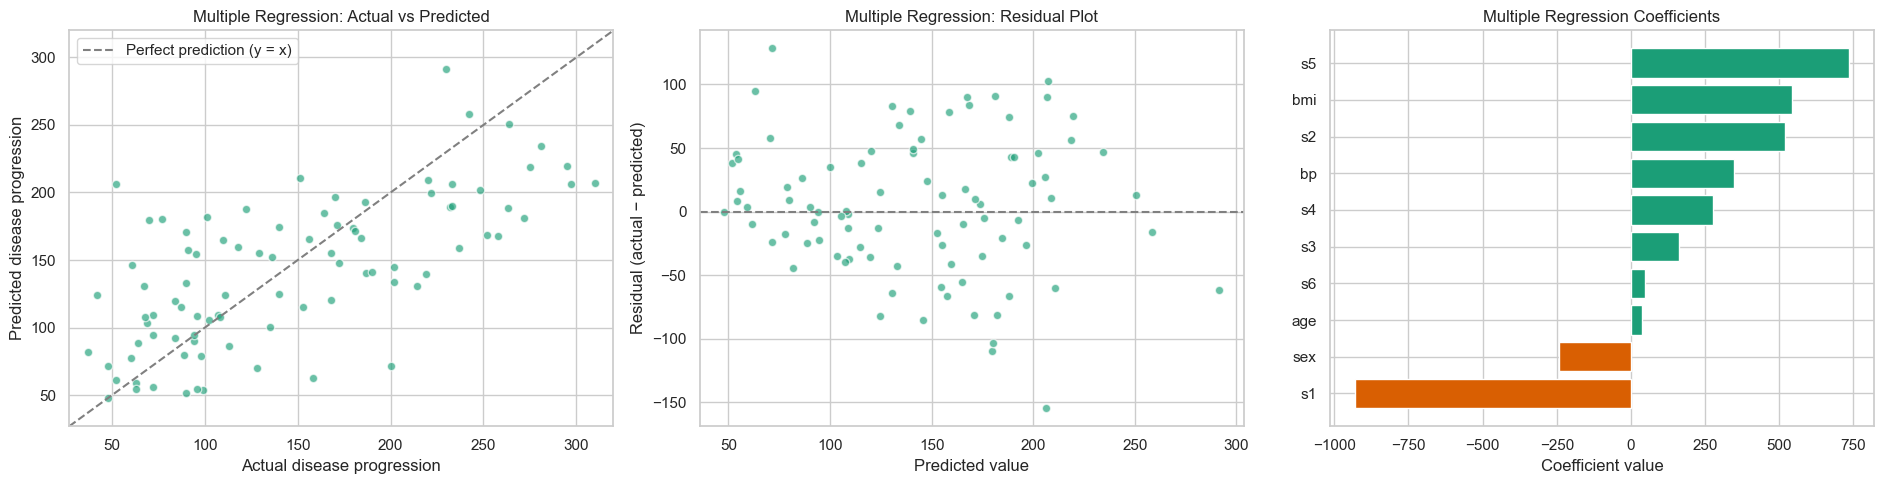

In [15]:
coef_mlr = pd.Series(mlr.coef_, index=diabetes.feature_names).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (a) actual vs predicted
plot_actual_vs_pred(y_test, y_pred_mlr, "Multiple Regression: Actual vs Predicted", ax=axes[0], color="#1b9e77")

# (b) residual plot
residuals = y_test - y_pred_mlr
axes[1].scatter(y_pred_mlr, residuals, alpha=.65, color="#1b9e77", edgecolor="white")
axes[1].axhline(0, ls="--", color="gray")
axes[1].set_xlabel("Predicted value"); axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Multiple Regression: Residual Plot")

# (c) coefficients
colors = ["#d95f02" if c < 0 else "#1b9e77" for c in coef_mlr]
axes[2].barh(coef_mlr.index, coef_mlr.values, color=colors)
axes[2].set_title("Multiple Regression Coefficients"); axes[2].set_xlabel("Coefficient value")
plt.tight_layout(); plt.show()

**Interpretation**
- Using all features roughly **doubles R²** (≈ 0.45 vs ≈ 0.23) and lowers RMSE from ~64 to ~54 compared with BMI alone, so the extra features carry real information.
- Training R² (≈ 0.53) and test R² (≈ 0.45) are reasonably close, and the cross-validated R² is similar, so the model is **not severely overfitting**.
- The residual plot shows points scattered around zero with no strong pattern, so the linear assumption is reasonable, although residuals spread a little wider for larger predictions.
- **Unstable coefficients:** `s1` gets a large negative coefficient while `s2` gets a large positive one, even though both are cholesterol measures that are 0.90 correlated. That is a classic sign of **multicollinearity** – the model trades the two off against each other. Ridge and Lasso address exactly this.
- The most influential features are `s5` (triglycerides), `bmi` and `bp`, which matches the correlation analysis.

## Step 4: Polynomial Regression

Polynomial regression adds powers and interaction terms of the features (e.g. $x_1^2$, $x_1 x_2$) and still fits them with linear regression. This lets the model capture **curved relationships**, but every extra degree adds many new features and increases the risk of **overfitting**.

The lab explores this in two parts:
- **4.1** Polynomial regression on **BMI only** (easy to visualize as a curve).
- **4.2** Polynomial regression on **all features** (degrees 1–3) to show how fast the number of features grows and how overfitting appears.

Polynomial features are **standardized** inside a pipeline so that high powers do not end up on wildly different scales.

### 4.1 Polynomial regression on BMI – degrees 1 to 15

In [16]:
degrees = range(1, 16)
poly_bmi_rows = []
for d in degrees:
    model = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_train_bmi, y_train)
    poly_bmi_rows.append({
        "Degree": d,
        "Train R2": r2_score(y_train, model.predict(X_train_bmi)),
        "Test R2": r2_score(y_test, model.predict(X_test_bmi)),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, model.predict(X_train_bmi))),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, model.predict(X_test_bmi))),
    })
poly_bmi_df = pd.DataFrame(poly_bmi_rows).set_index("Degree")
poly_bmi_df.round(4)

,Train R2,Test R2,Train RMSE,Test RMSE
Degree,,,,
1,0.3657,0.2334,62.0815,63.7325
2,0.3665,0.2290,62.0430,63.9142
3,0.3667,0.2329,62.0359,63.7530
4,0.3695,0.2023,61.8955,65.0088
5,0.3707,0.2288,61.8366,63.9206
6,0.3721,0.2489,61.7682,63.0839
7,0.3740,0.2086,61.6754,64.7541
8,0.3853,-0.4864,61.1159,88.7430
9,0.3853,-0.3600,61.1137,84.8842


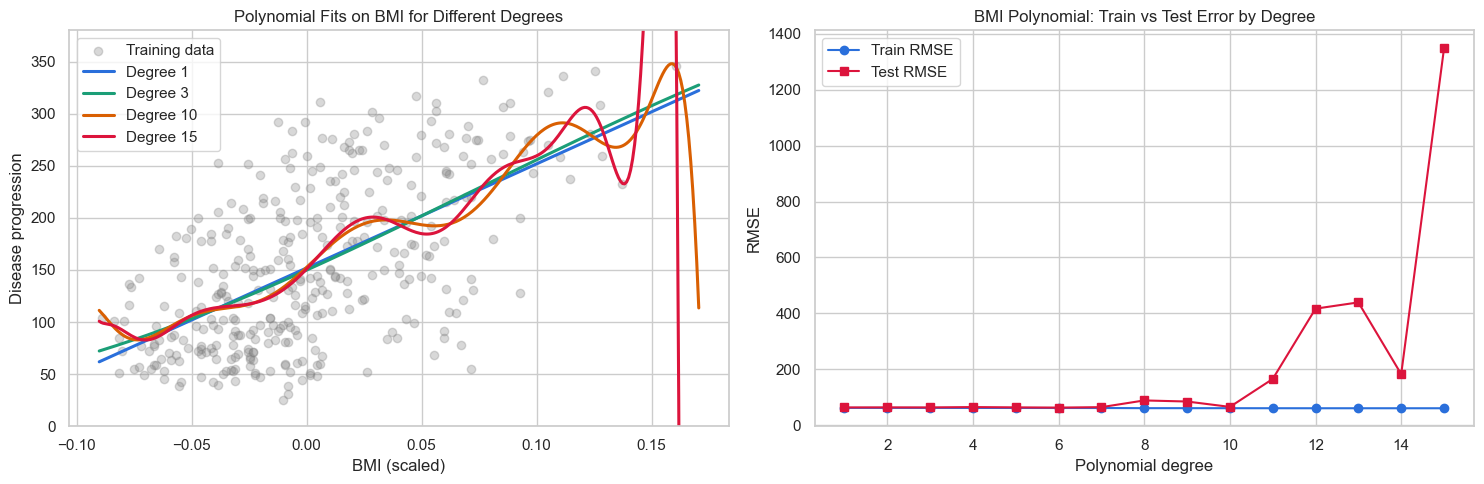

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) fitted curves for selected degrees
x_line = pd.DataFrame(np.linspace(X["bmi"].min(), X["bmi"].max(), 300), columns=["bmi"])
axes[0].scatter(X_train_bmi, y_train, alpha=.3, color="gray", label="Training data")
for d, c in zip([1, 3, 10, 15], ["#2a6fdb", "#1b9e77", "#d95f02", "crimson"]):
    m = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression()).fit(X_train_bmi, y_train)
    axes[0].plot(x_line, m.predict(x_line), lw=2.2, color=c, label=f"Degree {d}")
axes[0].set_ylim(0, 380)
axes[0].set_xlabel("BMI (scaled)"); axes[0].set_ylabel("Disease progression")
axes[0].set_title("Polynomial Fits on BMI for Different Degrees"); axes[0].legend()

# (b) train vs test RMSE by degree
axes[1].plot(poly_bmi_df.index, poly_bmi_df["Train RMSE"], "o-", label="Train RMSE", color="#2a6fdb")
axes[1].plot(poly_bmi_df.index, poly_bmi_df["Test RMSE"], "s-", label="Test RMSE", color="crimson")
axes[1].set_xlabel("Polynomial degree"); axes[1].set_ylabel("RMSE")
axes[1].set_title("BMI Polynomial: Train vs Test Error by Degree"); axes[1].legend()
plt.tight_layout(); plt.show()

**Interpretation (BMI only)**
- Degrees 1–3 give almost identical, smooth curves – the BMI–progression relationship is close to linear, so a higher degree adds little.
- As the degree increases, **training error keeps falling** (the model fits the training points more closely), but the **test error becomes unstable and then explodes** – from degree 8 onward test R² often goes negative, reaching about −43 at degree 15 (test RMSE ≈ 480 vs ≈ 64 for the straight line).
- At high degrees the curve **bends wildly at the edges** of the BMI range where there are few data points. It is fitting noise rather than the true pattern – a visual example of **overfitting**. A tiny improvement on training data costs a huge loss on new data.

### 4.2 Polynomial regression on all features – degrees 1, 2, 3

In [18]:
poly_all_rows, poly_models = [], {}
for d in [1, 2, 3]:
    model = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    poly_models[d] = model
    n_feats = model.named_steps["polynomialfeatures"].n_output_features_
    poly_all_rows.append({
        "Degree": d, "# Features": n_feats,
        "Train R2": r2_score(y_train, model.predict(X_train)),
        "Test R2": r2_score(y_test, model.predict(X_test)),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, model.predict(X_train))),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, model.predict(X_test))),
    })
poly_all_df = pd.DataFrame(poly_all_rows).set_index("Degree")
poly_all_df.round(4)

,# Features,Train R2,Test R2,Train RMSE,Test RMSE
Degree,,,,,
1,10,0.5279,0.4526,53.5588,53.8534
2,65,0.6062,0.4156,48.9197,55.6420
3,285,0.8773,-14.5613,27.3060,287.1342


In [19]:
# Store the degree-2 and degree-3 models in the comparison table
y_pred_poly2 = poly_models[2].predict(X_test)
y_pred_poly3 = poly_models[3].predict(X_test)
evaluate_model("Polynomial deg 2 (all features)", y_test, y_pred_poly2); print()
_ = evaluate_model("Polynomial deg 3 (all features)", y_test, y_pred_poly3)

Polynomial deg 2 (all features)
  MAE :    43.58
  MSE :  3096.03
  RMSE:    55.64
  R²  :   0.4156

Polynomial deg 3 (all features)
  MAE :   164.85
  MSE : 82446.05
  RMSE:   287.13
  R²  : -14.5613


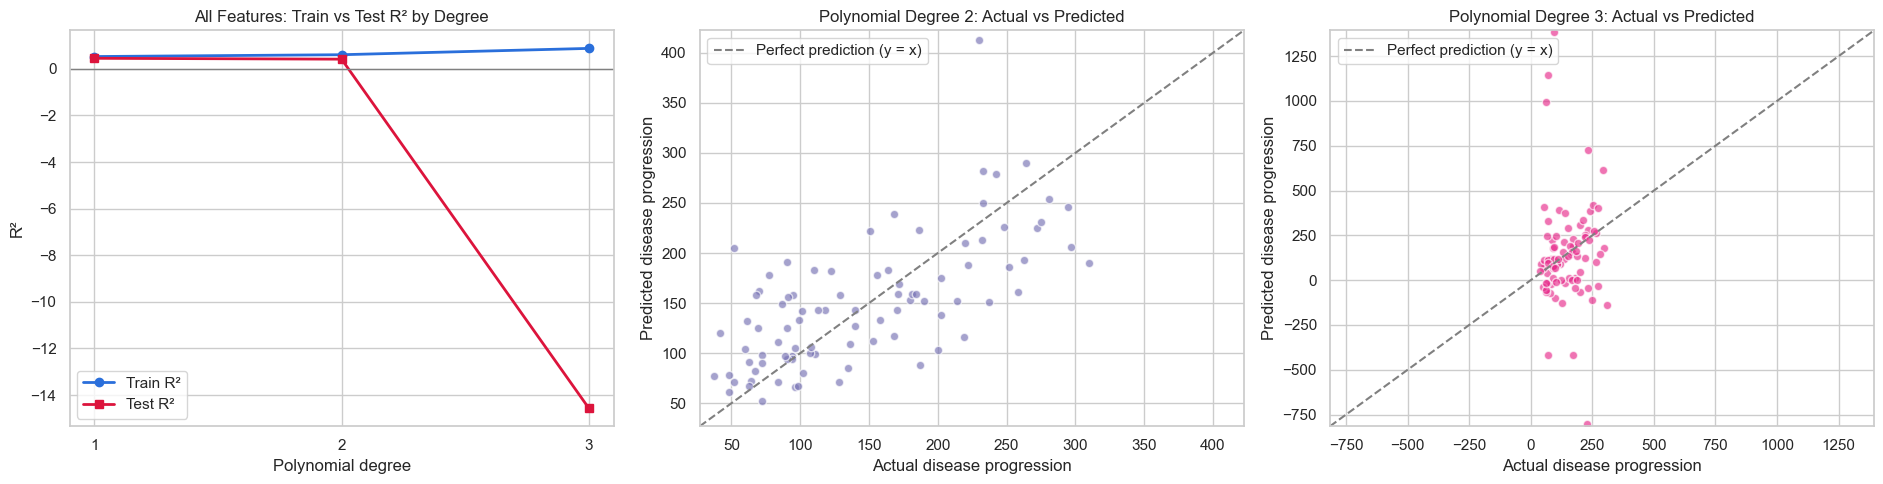

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (a) train vs test R2 by degree
axes[0].plot(poly_all_df.index, poly_all_df["Train R2"], "o-", lw=2, label="Train R²", color="#2a6fdb")
axes[0].plot(poly_all_df.index, poly_all_df["Test R2"], "s-", lw=2, label="Test R²", color="crimson")
axes[0].axhline(0, color="gray", lw=1)
axes[0].set_xticks([1, 2, 3]); axes[0].set_xlabel("Polynomial degree"); axes[0].set_ylabel("R²")
axes[0].set_title("All Features: Train vs Test R² by Degree"); axes[0].legend()

# (b) & (c) actual vs predicted for degree 2 and 3
plot_actual_vs_pred(y_test, y_pred_poly2, "Polynomial Degree 2: Actual vs Predicted", ax=axes[1], color="#7570b3")
plot_actual_vs_pred(y_test, y_pred_poly3, "Polynomial Degree 3: Actual vs Predicted", ax=axes[2], color="#e7298a")
plt.tight_layout(); plt.show()

**Interpretation (all features)** – this is the clearest overfitting example in the lab:

| Degree | What happens |
|---|---|
| **1** | 10 features. Same as multiple regression – a balanced fit. |
| **2** | 65 features (squares + pairwise interactions). Training R² rises to ≈ 0.61 but **test R² drops** to ≈ 0.42: the model starts memorizing noise. |
| **3** | **285 features for only 353 training rows.** Training R² jumps to ≈ 0.88 while **test R² collapses to ≈ −13.7** (RMSE ≈ 279) – far worse than simply predicting the mean. This is **severe overfitting**. |

- **Underfitting** was seen with simple linear regression (one feature, low R² on both train and test).
- **Overfitting** is seen here: a widening gap between training and test performance as model complexity grows.
- **Comparison with earlier models:** Simple Linear (BMI) has R² ≈ 0.23, Multiple Regression ≈ 0.45, Polynomial degree 2 ≈ 0.42 and Polynomial degree 3 ≈ −13.7. Polynomial regression without regularization therefore does **not** beat multiple regression on this dataset.
- The best plain polynomial model is the lowest-complexity one, which shows that **extra flexibility without control hurts** on a small dataset. The next step shows how regularization can make the degree-2 feature set usable.

## Step 5: Regularization with Ridge and Lasso Regression

Regularization adds a **penalty on coefficient size** to the least-squares loss, discouraging overly complex models:

- **Ridge (L2):** $\displaystyle \min_\beta \sum (y_i - \hat{y}_i)^2 + \alpha \sum \beta_j^2$ – shrinks all coefficients **toward** zero but rarely to exactly zero. Handles correlated features by spreading weight between them.
- **Lasso (L1):** $\displaystyle \min_\beta \frac{1}{2n}\sum (y_i - \hat{y}_i)^2 + \alpha \sum |\beta_j|$ – can shrink coefficients to **exactly zero**, performing automatic **feature selection**.

**The role of `alpha`:**
- `alpha = 0` → no penalty (same as ordinary linear regression).
- Small `alpha` → little shrinkage, low bias, high variance (risk of overfitting).
- Large `alpha` → heavy shrinkage, high bias, low variance (risk of underfitting).

We apply both methods in two settings:
- **5.1** On the **10 original features** (compare with multiple regression).
- **5.2** On the **degree-2 polynomial features** (65 features), where the unregularized model overfit.

Alpha is tuned with **5-fold cross-validation on the training set only** (`RidgeCV` / `LassoCV`), so the test set stays untouched for the final evaluation.

### 5.1 Effect of alpha on the original 10 features

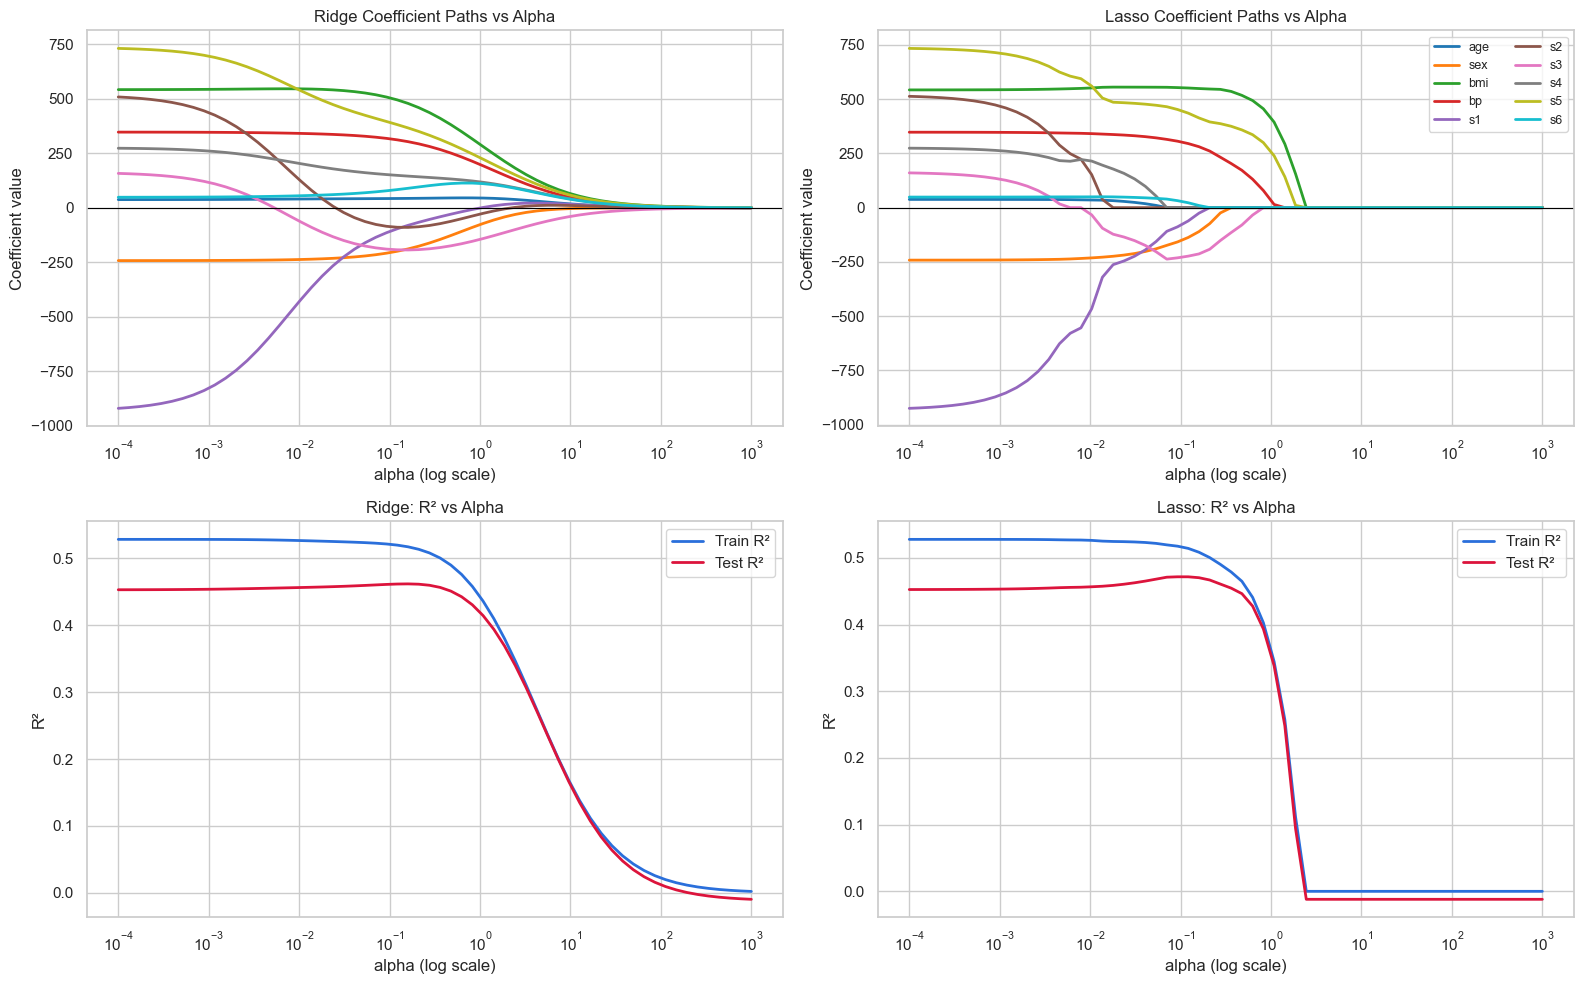

In [21]:
alphas = np.logspace(-4, 3, 60)   # alpha from 0.0001 to 1000

ridge_coefs, lasso_coefs = [], []
ridge_scores, lasso_scores = {"train": [], "test": []}, {"train": [], "test": []}

for a in alphas:
    r = Ridge(alpha=a).fit(X_train, y_train)
    l = Lasso(alpha=a, max_iter=50000).fit(X_train, y_train)
    ridge_coefs.append(r.coef_); lasso_coefs.append(l.coef_)
    ridge_scores["train"].append(r2_score(y_train, r.predict(X_train))); ridge_scores["test"].append(r2_score(y_test, r.predict(X_test)))
    lasso_scores["train"].append(r2_score(y_train, l.predict(X_train))); lasso_scores["test"].append(r2_score(y_test, l.predict(X_test)))

ridge_coefs, lasso_coefs = np.array(ridge_coefs), np.array(lasso_coefs)
palette = sns.color_palette("tab10", 10)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
# Coefficient paths
for i, f in enumerate(diabetes.feature_names):
    axes[0, 0].plot(alphas, ridge_coefs[:, i], label=f, color=palette[i], lw=2)
    axes[0, 1].plot(alphas, lasso_coefs[:, i], label=f, color=palette[i], lw=2)
for ax, t in zip(axes[0], ["Ridge", "Lasso"]):
    ax.set_xscale("log"); ax.axhline(0, color="black", lw=.8)
    ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("Coefficient value")
    ax.set_title(f"{t} Coefficient Paths vs Alpha")
axes[0, 1].legend(ncol=2, fontsize=9, loc="upper right")

# Train/test R2 vs alpha
for ax, s, t in zip(axes[1], [ridge_scores, lasso_scores], ["Ridge", "Lasso"]):
    ax.plot(alphas, s["train"], label="Train R²", color="#2a6fdb", lw=2)
    ax.plot(alphas, s["test"], label="Test R²", color="crimson", lw=2)
    ax.set_xscale("log"); ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("R²")
    ax.set_title(f"{t}: R² vs Alpha"); ax.legend()
plt.tight_layout(); plt.show()

**How alpha changes model behavior**
- **Ridge coefficient paths:** as alpha grows, every coefficient shrinks smoothly toward zero, but none reaches exactly zero. Notice that the large opposing `s1`/`s2` coefficients from multiple regression are pulled together quickly – Ridge **stabilizes correlated features**.
- **Lasso coefficient paths:** coefficients hit **exactly zero one after another**. The redundant cholesterol feature `s2` is removed first, then `s4`, `age`, `s1`, `s6` and `sex`; `bmi` and `s5` survive the longest – they are the most important predictors.
- **R² vs alpha:** for small alpha both models behave like ordinary linear regression. For very large alpha all coefficients are crushed and R² falls toward 0 (**underfitting**). In between there is a sweet spot; Lasso's R² drops off more sharply because it removes features entirely.

In [22]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Tune alpha by cross-validation on the TRAINING data only
ridge_cv = RidgeCV(alphas=alphas, cv=cv).fit(X_train, y_train)
lasso_cv = LassoCV(alphas=alphas, cv=cv, max_iter=50000, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Best Ridge alpha (CV): {ridge_cv.alpha_:.4f}")
print(f"Best Lasso alpha (CV): {lasso_cv.alpha_:.4f}\n")

y_pred_ridge = ridge_cv.predict(X_test)
y_pred_lasso = lasso_cv.predict(X_test)
evaluate_model("Ridge (10 features)", y_test, y_pred_ridge); print()
_ = evaluate_model("Lasso (10 features)", y_test, y_pred_lasso)

coef_table = pd.DataFrame({"Linear": mlr.coef_, "Ridge": ridge_cv.coef_, "Lasso": lasso_cv.coef_},
                          index=diabetes.feature_names).round(2)
print("\nCoefficient comparison:")
coef_table

Best Ridge alpha (CV): 0.0020
Best Lasso alpha (CV): 0.0310

Ridge (10 features)
  MAE :    42.81
  MSE :  2892.65
  RMSE:    53.78
  R²  :   0.4540

Lasso (10 features)
  MAE :    42.83
  MSE :  2846.21
  RMSE:    53.35
  R²  :   0.4628

Coefficient comparison:


,Linear,Ridge,Lasso
age,37.90,38.95,24.16
sex,-241.96,-240.78,-211.44
bmi,542.43,544.83,555.25
bp,347.70,345.98,331.28
s1,-931.49,-744.64,-223.71
s2,518.06,372.55,-0.00
s3,163.42,79.78,-152.05
s4,275.32,249.06,132.29
s5,736.20,663.99,480.62
s6,48.67,50.67,47.09


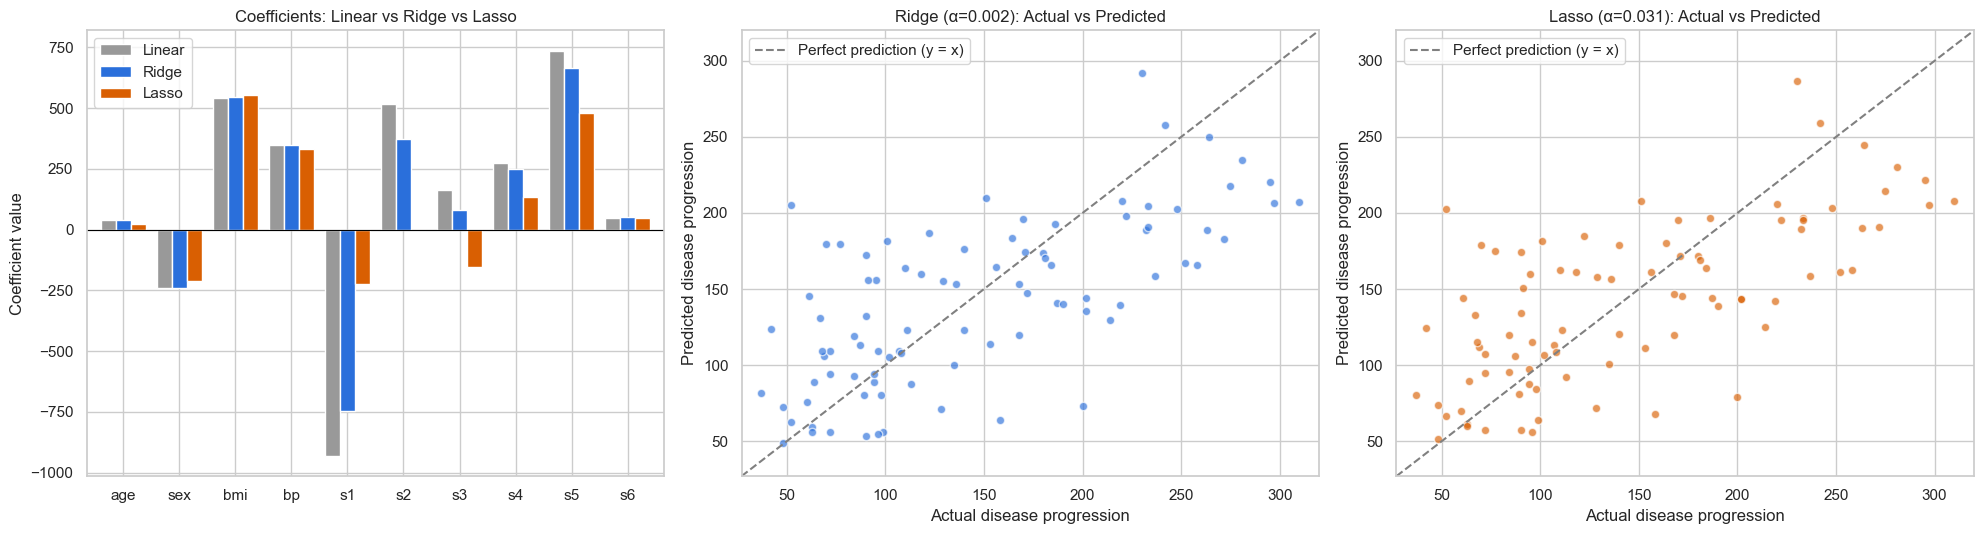

Features removed by Lasso (coefficient = 0): ['s2']


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Coefficient comparison bar chart
coef_table.plot(kind="bar", ax=axes[0], color=["#999999", "#2a6fdb", "#d95f02"], width=.8)
axes[0].axhline(0, color="black", lw=.8)
axes[0].set_title("Coefficients: Linear vs Ridge vs Lasso"); axes[0].set_ylabel("Coefficient value")
axes[0].tick_params(axis="x", rotation=0)

plot_actual_vs_pred(y_test, y_pred_ridge, f"Ridge (α={ridge_cv.alpha_:.3f}): Actual vs Predicted", ax=axes[1], color="#2a6fdb")
plot_actual_vs_pred(y_test, y_pred_lasso, f"Lasso (α={lasso_cv.alpha_:.3f}): Actual vs Predicted", ax=axes[2], color="#d95f02")
plt.tight_layout(); plt.show()

print("Features removed by Lasso (coefficient = 0):",
      list(coef_table.index[coef_table["Lasso"] == 0]) or "none")

**Interpretation (10 features)**
- With only 10 features and 353 training rows, plain multiple regression was not badly overfitting, so Ridge and Lasso give **similar test performance** to it – regularization cannot add much where there is little variance to remove.
- Cross-validation picked a **very small Ridge alpha** (≈ 0.002), so Ridge stays close to ordinary least squares but still pulls the opposite-sign `s1`/`s2` coefficients in (−931 → −745 and 518 → 373).
- **Lasso** makes a bigger change: it drops `s2` completely, shrinks `s1` from −931 to about −224, and flips `s3` (HDL) to a **negative** coefficient that now matches its negative correlation with the target. The model is simpler and easier to interpret, and its test R² is even slightly higher (≈ 0.463 vs 0.453).

## Step 6: Model Comparison and Analysis

### 6.1 Summary table of test-set performance

In [27]:
summary = pd.DataFrame(results).set_index("Model")
summary.style.format({"MAE": "{:.2f}", "MSE": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.4f}"}) \
       .highlight_min(subset=["MAE", "MSE", "RMSE"], color="#c7f0d1") \
       .highlight_max(subset=["R2"], color="#c7f0d1")

,MAE,MSE,RMSE,R2
Model,,,,
Simple Linear (BMI),52.26,4061.83,63.73,0.2334
Multiple Linear (all 10),42.79,2900.19,53.85,0.4526
Polynomial deg 2 (all features),43.58,3096.03,55.64,0.4156
Polynomial deg 3 (all features),164.85,82446.05,287.13,-14.5613
Ridge (10 features),42.81,2892.65,53.78,0.4540
Lasso (10 features),42.83,2846.21,53.35,0.4628
Ridge + Poly deg 2,41.07,2628.87,51.27,0.5038
Lasso + Poly deg 2,41.59,2594.89,50.94,0.5102


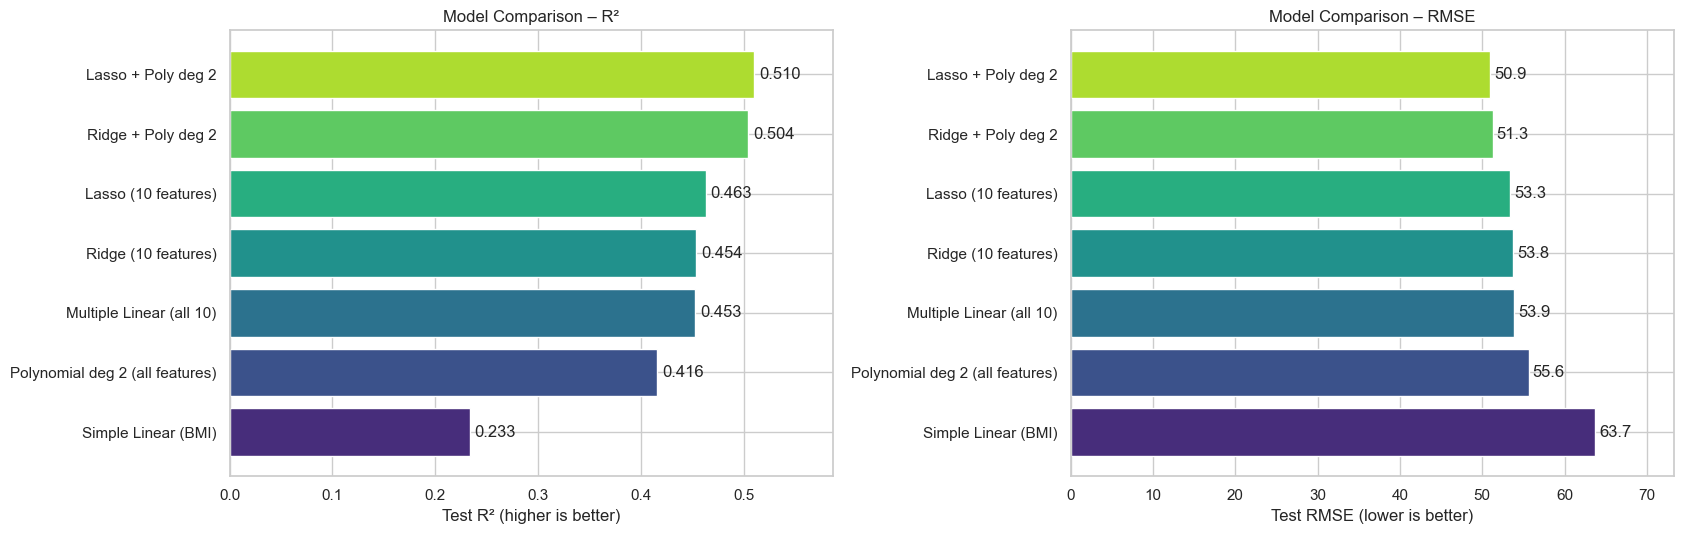

Polynomial deg 3 (excluded above): R² = -14.56, RMSE = 287.1


In [28]:
# Visual comparison. Degree-3 polynomial is excluded from the bar charts because its huge error would hide the differences between the other models.
plot_df = summary.drop(index="Polynomial deg 3 (all features)").sort_values("R2")

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
bar_colors = sns.color_palette("viridis", len(plot_df))
axes[0].barh(plot_df.index, plot_df["R2"], color=bar_colors)
for i, v in enumerate(plot_df["R2"]):
    axes[0].text(v + .005, i, f"{v:.3f}", va="center")
axes[0].set_xlabel("Test R² (higher is better)"); axes[0].set_title("Model Comparison – R²")
axes[0].set_xlim(0, plot_df["R2"].max() * 1.15)

axes[1].barh(plot_df.index, plot_df["RMSE"], color=bar_colors)
for i, v in enumerate(plot_df["RMSE"]):
    axes[1].text(v + .5, i, f"{v:.1f}", va="center")
axes[1].set_xlabel("Test RMSE (lower is better)"); axes[1].set_title("Model Comparison – RMSE")
axes[1].set_xlim(0, plot_df["RMSE"].max() * 1.15)
plt.tight_layout(); plt.show()

print(f"Polynomial deg 3 (excluded above): R² = {summary.loc['Polynomial deg 3 (all features)', 'R2']:.2f}, "
      f"RMSE = {summary.loc['Polynomial deg 3 (all features)', 'RMSE']:.1f}")

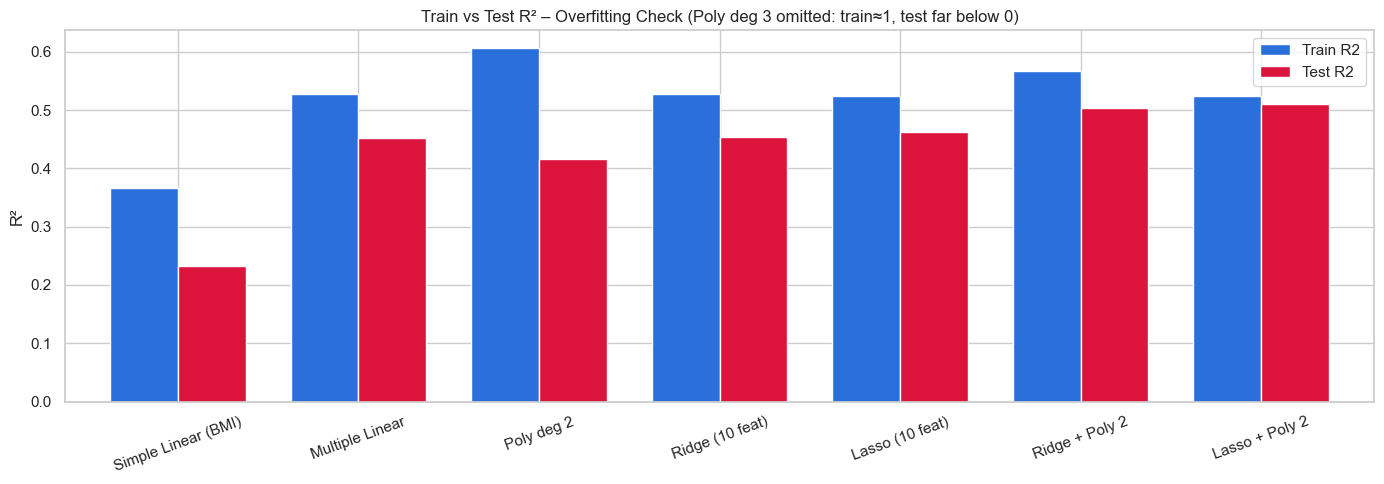

,Train R2,Test R2,Gap (Train − Test)
Simple Linear (BMI),0.3657,0.2334,0.1324
Multiple Linear,0.5279,0.4526,0.0753
Poly deg 2,0.6062,0.4156,0.1905
Poly deg 3,0.8773,-14.5613,15.4386
Ridge (10 feat),0.5277,0.4540,0.0737
Lasso (10 feat),0.5240,0.4628,0.0612
Ridge + Poly 2,0.5670,0.5038,0.0632
Lasso + Poly 2,0.5246,0.5102,0.0144


In [29]:
# Overfitting check: train vs test R2 for the main models
fit_check = {
    "Simple Linear (BMI)":   (slr,        X_train_bmi, X_test_bmi),
    "Multiple Linear":       (mlr,        X_train,     X_test),
    "Poly deg 2":            (poly_models[2], X_train, X_test),
    "Poly deg 3":            (poly_models[3], X_train, X_test),
    "Ridge (10 feat)":       (ridge_cv,   X_train,     X_test),
    "Lasso (10 feat)":       (lasso_cv,   X_train,     X_test),
    "Ridge + Poly 2":        (ridge_poly, X_train,     X_test),
    "Lasso + Poly 2":        (lasso_poly, X_train,     X_test),
}
gap_df = pd.DataFrame({name: {"Train R2": r2_score(y_train, m.predict(Xtr)),
                              "Test R2":  r2_score(y_test,  m.predict(Xte))}
                       for name, (m, Xtr, Xte) in fit_check.items()}).T
gap_df["Gap (Train − Test)"] = gap_df["Train R2"] - gap_df["Test R2"]

plot_gap = gap_df.drop(index="Poly deg 3")
ax = plot_gap[["Train R2", "Test R2"]].plot(kind="bar", figsize=(14, 5), color=["#2a6fdb", "crimson"], width=.75)
ax.set_ylabel("R²"); ax.set_title("Train vs Test R² – Overfitting Check (Poly deg 3 omitted: train≈1, test far below 0)")
ax.tick_params(axis="x", rotation=20); plt.tight_layout(); plt.show()
gap_df.round(4)

### 6.2 Discussion

#### How well did each model perform?
- **Simple Linear Regression (BMI)** – the weakest of the reasonable models (R² ≈ 0.23). BMI is the single best predictor, but one variable cannot explain disease progression. **Underfits.**
- **Multiple Regression** – a large improvement (R² ≈ 0.45, RMSE ≈ 54). Using all ten measurements captures most of the information a linear model can extract. A solid, simple baseline.
- **Polynomial Regression** – adding non-linear terms **did not help on its own**. Degree 2 (65 features) already performs worse on the test set than multiple regression, and degree 3 (285 features) fails completely with a negative test R², even though its training R² is near perfect.
- **Ridge and Lasso (10 features)** – essentially tie with multiple regression on accuracy, but with **smaller, more stable coefficients**; Lasso also removes a few features.
- **Ridge and Lasso on polynomial features** – the **best performers**. Regularization rescued the degree-2 model, lifting test R² to ≈ 0.50 (Ridge) and ≈ 0.51 (Lasso) and cutting RMSE to ≈ 51, versus ≈ 54 for multiple regression. Lasso did this with only 13 of the 65 terms.

The linear-type models sit at test R² ≈ 0.45–0.46 and the regularized polynomial models at ≈ 0.50–0.51. These differences are real but modest; with an 89-row test set, results would shift a little with a different random split.

#### Which models handled overfitting or improved performance?
- **Overfitting appeared** in high-degree polynomial models, shown by a growing gap between training and test R² (and test R² below zero for degree 3).
- **Ridge and Lasso controlled it** by penalizing large coefficients. Cross-validated alpha found the balance point between overfitting (alpha too small) and underfitting (alpha too large).
- **Lasso** added the benefit of **automatic feature selection**. Lasso + polynomial degree 2 had both the highest test R² and the smallest train–test gap (≈ 0.01) of any model.
- **Ridge** was the most reliable way to handle the **multicollinearity** between `s1`, `s2`, `s3` and `s4`.

#### Insights about the Diabetes dataset
1. **BMI, `s5` (log triglycerides) and blood pressure** are consistently the strongest predictors of disease progression – they have the highest correlations, the largest coefficients, and are the last to be removed by Lasso.
2. **HDL cholesterol (`s3`)** has a protective (negative) association with progression.
3. The cholesterol-related serum features are **highly correlated with each other**, which made ordinary regression coefficients unstable and misleading; regularization gives a more trustworthy picture.
4. The relationship between the features and the target is **mostly linear** – a few weak non-linear effects (e.g. `bmi²`, `bmi × bp`) exist, but they only add value once regularization removes the noisy terms around them.
5. Even the best model explains only about **half of the variance** (R² ≈ 0.51). Disease progression depends on factors not in these 10 baseline measurements (genetics, treatment, lifestyle), so there is a natural ceiling on how accurate any model can be with this data.
6. With only **442 samples**, model complexity must be kept in check – this dataset is a good illustration of why simpler or regularized models often beat flexible ones on small data.

### 6.3 Conclusion
Multiple regression provides a strong, interpretable baseline. Polynomial expansion shows how quickly a model can overfit when the number of features approaches the number of samples. Ridge and Lasso demonstrate that **regularization, with alpha tuned by cross-validation, is an effective way to control model complexity** – Ridge by shrinking correlated coefficients, Lasso by additionally selecting a compact set of features. For this dataset, **Lasso on degree-2 polynomial features** gave the best result (R² ≈ 0.51, RMSE ≈ 50.9) while using only a small set of terms. If maximum simplicity is preferred, **Lasso on the original 10 features** is a strong alternative (R² ≈ 0.46) that is very easy to interpret.